# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech

## Business Understanding
Jaya Jaya Institut ingin memahami faktor yang berkaitan dengan siswa yang tidak menyelesaikan studi dan memprioritaskan dukungan. Analisis ini menjawab komposisi status akhir, hubungan indikator akademik/administratif dengan status, dan kelayakan model baseline untuk menandai risiko dropout.

### Tujuan dan batasan
Target operasional notebook adalah klasifikasi biner `Dropout` versus status lain (`Graduate` dan `Enrolled`). Data mencakup hasil hingga semester kedua sehingga model ini bukan prediksi dini sebelum semester berjalan selesai. Korelasi dan feature importance tidak membuktikan sebab-akibat.

- Nama: Gregorius Christian Sunaryo
- Email: christian10rks@gmail.com
- Id Dicoding: 

## Persiapan

### Menyiapkan library yang dibutuhkan

In [33]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

### Menyiapkan data yang akan digunakan

In [34]:
student_performance_df = pd.read_csv(
    "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/students_performance/data.csv",
    sep=";",
    encoding="utf-8-sig"
)

student_performance_df.head()

,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Admission_grade,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,Curricular_units_1st_sem_credited,Curricular_units_1st_sem_enrolled,Curricular_units_1st_sem_evaluations,Curricular_units_1st_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_1st_sem_without_evaluations,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding

In [35]:
# Struktur dataset
rows, cols = student_performance_df.shape

print(f"Ukuran dataset: {rows:,} baris × {cols} kolom")
student_performance_df.info()

Ukuran dataset: 4,424 baris × 37 kolom
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification   

In [36]:
# Kualitas data
missing_values = student_performance_df.isna().sum()
duplicates = student_performance_df.duplicated().sum()

print(f"\nTotal nilai kosong  : {missing_values.sum():,}")
print(f"Jumlah baris duplikat: {duplicates:,}")

display(
    missing_values.sort_values(ascending=False)
    .head(10)
    .to_frame("Nilai Kosong")
)


Total nilai kosong  : 0
Jumlah baris duplikat: 0


,Nilai Kosong
Marital_status,0
Application_mode,0
Application_order,0
Course,0
Daytime_evening_attendance,0
Previous_qualification,0
Previous_qualification_grade,0
Nacionality,0
Mothers_qualification,0
Fathers_qualification,0


In [37]:
# Distribusi status mahasiswa
status_order = ["Dropout", "Enrolled", "Graduate"]

status_distribution = (
    student_performance_df["Status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis("Status")
    .to_frame("Jumlah")
)

status_distribution["Proporsi"] = (
    status_distribution["Jumlah"] / rows
)

display(
    status_distribution.style.format({
        "Jumlah": "{:,.0f}",
        "Proporsi": "{:.1%}",
    })
)

,Jumlah,Proporsi
Status,,
Dropout,"1,421",32.1%
Enrolled,794,17.9%
Graduate,"2,209",49.9%


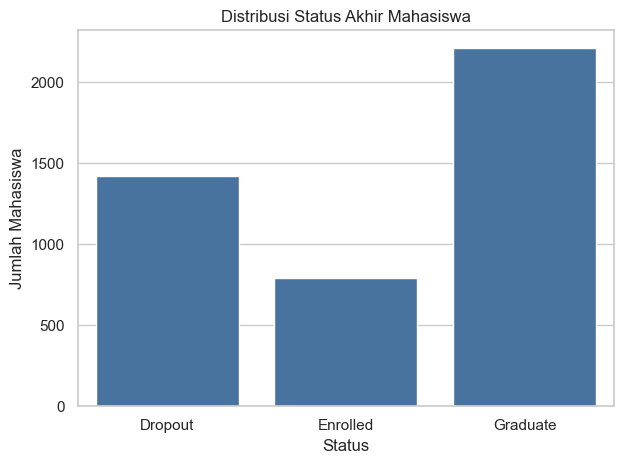

In [38]:
# Visualisasi distribusi status
sns.countplot(
    data=student_performance_df,
    x="Status",
    order=status_order,
    color="#3973ac",
)

plt.title("Distribusi Status Akhir Mahasiswa")
plt.xlabel("Status")
plt.ylabel("Jumlah Mahasiswa")
plt.tight_layout()
plt.show()

In [39]:
# Rata-rata capaian akademik berdasarkan status
academic_features = [
    "Curricular_units_1st_sem_approved",
    "Curricular_units_2nd_sem_approved",
    "Curricular_units_1st_sem_grade",
    "Curricular_units_2nd_sem_grade",
]

academic_summary = (
    student_performance_df
    .groupby("Status")[academic_features]
    .mean()
    .reindex(status_order)
    .round(2)
)

display(academic_summary)


,Curricular_units_1st_sem_approved,Curricular_units_2nd_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_2nd_sem_grade
Status,,,,
Dropout,2.55,1.94,7.26,5.90
Enrolled,4.32,4.06,11.13,11.12
Graduate,6.23,6.18,12.64,12.70


## Data Preparation / Preprocessing
Pilih fitur akademik semester 1–2 dan indikator administrasi yang tersedia saat status akhir dinilai. Target tiga kelas diubah menjadi indikator Dropout. Data dibagi secara stratified agar proporsi kelas terjaga; observasi yang memiliki nilai kosong pada kolom terpilih dihapus.

In [40]:
# Konfigurasi target dan fitur
target = "Status"
features = [
    "Age_at_enrollment",
    "Tuition_fees_up_to_date",
    "Scholarship_holder",
    "Debtor",
    "Curricular_units_1st_sem_enrolled",
    "Curricular_units_1st_sem_approved",
    "Curricular_units_1st_sem_grade",
    "Curricular_units_2nd_sem_enrolled",
    "Curricular_units_2nd_sem_approved",
    "Curricular_units_2nd_sem_grade",
]

# Siapkan data dan target biner
data = student_performance_df[features + [target]].dropna().copy()
X = data[features]
y = data[target].eq("Dropout").astype(int)

# Pertahankan proporsi target pada data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Data latih: {len(X_train):,} | data uji: {len(X_test):,}")

Data latih: 3,539 | data uji: 885


## Modeling
Menggunakan model random forest untuk menangkap hubungan non-linear

In [41]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print(f"Akurasi holdout: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not dropout", "Dropout"],
    digits=3,
))
print("Confusion matrix [actual rows, predicted columns]:")
print(confusion_matrix(y_test, y_pred))

Akurasi holdout: 0.872
              precision    recall  f1-score   support

 Not dropout      0.904     0.908     0.906       601
     Dropout      0.804     0.796     0.800       284

    accuracy                          0.872       885
   macro avg      0.854     0.852     0.853       885
weighted avg      0.872     0.872     0.872       885

Confusion matrix [actual rows, predicted columns]:
[[546  55]
 [ 58 226]]


## Evaluation
Evaluasi menggunakan precision, recall, f1 score

In [42]:
# Classification report
evaluation = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Not dropout", "Dropout"],
        output_dict=True,
        zero_division=0,
    )
).T

print("Classification Report:")
display(evaluation.round(3))

Classification Report:


,precision,recall,f1-score,support
Not dropout,0.904,0.908,0.906,601.000
Dropout,0.804,0.796,0.800,284.000
accuracy,0.872,0.872,0.872,0.872
macro avg,0.854,0.852,0.853,885.000
weighted avg,0.872,0.872,0.872,885.000


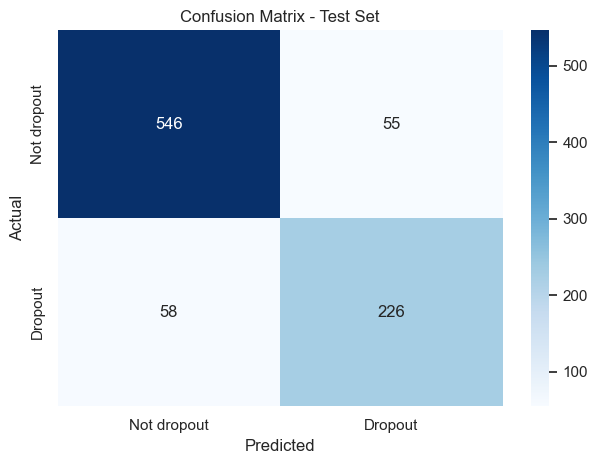

In [43]:
# Confusion matrix
class_labels = ["Not dropout", "Dropout"]

sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
)

plt.title("Confusion Matrix - Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

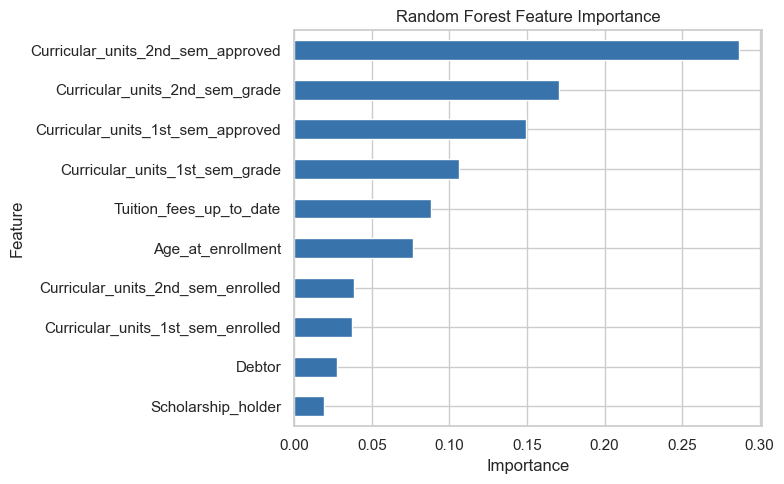

In [44]:
# Feature importance
importance = (
    pd.Series(model.feature_importances_, index=features)
    .sort_values(ascending=False)
)

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    color="#3973ac",
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [45]:
# Latih model final pada seluruh data untuk digunakan aplikasi
final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
final_model.fit(data[features], y)

# Simpan artefak di folder model pada root proyek
project_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "app.py").is_file()),
    Path.cwd(),
)
model_path = project_root / "model" / "model.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, model_path, compress=3)

# Verifikasi bahwa artefak dapat dimuat dan menghasilkan prediksi yang sama
loaded_model = joblib.load(model_path)
sample = data[features].head(10)
assert (final_model.predict(sample) == loaded_model.predict(sample)).all()
print(f"Model tersimpan: {model_path}")
print(f"Ukuran artefak: {model_path.stat().st_size:,} bytes")

Model tersimpan: e:\Submission Penerapan Data Science\submission-kedua\model\model.joblib
Ukuran artefak: 4,140,918 bytes


## Conclusion dan Action Items
Pada data historis, capaian unit dan nilai semester berkaitan dengan status akhir siswa, sementara status tunggakan dan pembayaran juga membantu membedakan profil risiko. Gunakan hasil dashboard dan prediksi untuk memprioritaskan percakapan dukungan, bukan untuk menjatuhkan sanksi atau membuat keputusan otomatis. Karena fitur model memuat informasi hingga semester kedua, model ini belum dapat diklaim sebagai peringatan dini.

1. Tawarkan konsultasi akademik ketika jumlah unit lulus atau nilai siswa menurun.
2. Arahkan siswa dengan kendala pembayaran ke dukungan finansial dan evaluasi kebutuhan bantuan.
3. Uji model pada kohort berikutnya, pantau recall/precision dan kalibrasi, serta audit performa lintas kelompok.
4. Kumpulkan snapshot semester dengan ID pseudonim agar tren siswa dan dampak intervensi dapat dievaluasi.

In [46]:
# Top 10 features
print("Top 10 Feature Importance:")
display(importance.head(10).to_frame("Importance").round(4))

Top 10 Feature Importance:


,Importance
Curricular_units_2nd_sem_approved,0.2868
Curricular_units_2nd_sem_grade,0.1707
Curricular_units_1st_sem_approved,0.1496
Curricular_units_1st_sem_grade,0.1059
Tuition_fees_up_to_date,0.0884
Age_at_enrollment,0.0763
Curricular_units_2nd_sem_enrolled,0.0383
Curricular_units_1st_sem_enrolled,0.0375
Debtor,0.0277
Scholarship_holder,0.0188
